In [2]:
import os
import urllib.request
import zipfile

url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
if not os.path.exists("ml-100k.zip"):
    urllib.request.urlretrieve(url, "ml-100k.zip")
    print("архив скачан!!")
else:
    print("архив уже существует(")

with zipfile.ZipFile("ml-100k.zip", 'r') as zip_ref:
    zip_ref.extractall(".")

print("готово!")

архив скачан!!
готово!



Popularity-based (мин. 50 оценок):


,title,avg_rating,count
0,"Close Shave, A (1995)",4.491071,112
1,Schindler's List (1993),4.466443,298
2,"Wrong Trousers, The (1993)",4.466102,118
3,Casablanca (1942),4.456790,243
4,Wallace & Gromit: The Best of Aardman Animatio...,4.447761,67


/tmp/ipykernel_872/1940850129.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='avg_rating', y='title', data=top_10, palette='viridis')


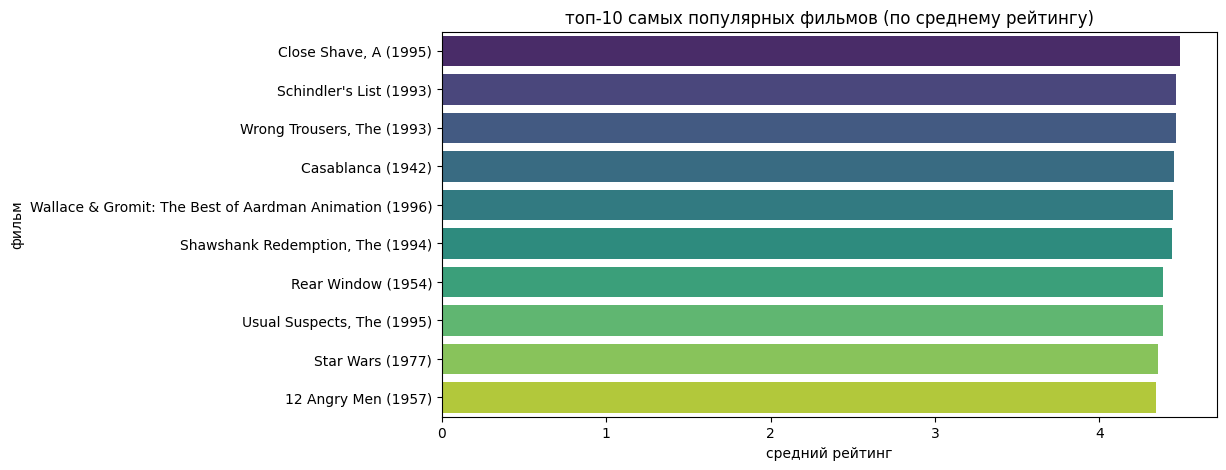


Genre-based для 'Toy Story (1995)':


,title,match_count
819,Space Jam (1996),3
94,Aladdin (1992),3
421,Aladdin and the King of Thieves (1996),3
992,Hercules (1997),3
1218,"Goofy Movie, A (1995)",3



Content-based рекомендации для 'Toy Story (1995)':


,title
421,Aladdin and the King of Thieves (1996)
101,"Aristocats, The (1970)"
403,Pinocchio (1940)
624,"Sword in the Stone, The (1963)"
945,"Fox and the Hound, The (1981)"



Collaborative filtering  для 'Toy Story (1995)':


,title
49,Star Wars (1977)
116,"Rock, The (1996)"
120,Independence Day (ID4) (1996)
180,Return of the Jedi (1983)
404,Mission: Impossible (1996)


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ratings = pd.read_csv('ml-100k/u.data', sep='\t',
                      names=['user_id', 'item_id', 'rating', 'timestamp'])

movies = pd.read_csv('ml-100k/u.item', sep='|', encoding='latin-1', header=None)
movie_cols = ['item_id', 'title', 'release_date', 'video_release', 'imdb_url']
genre_cols = ['unknown', 'Action', 'Adventure', 'Animation', 'Children',
              'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy',
              'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance',
              'Sci-Fi', 'Thriller', 'War', 'Western']
movies.columns = movie_cols + genre_cols

def get_popular_movies(top_n=10):
    movie_stats = ratings.groupby('item_id').agg(
        avg_rating=('rating', 'mean'),
        count=('rating', 'size')
    ).reset_index()
    movie_stats = movie_stats[movie_stats['count'] >= 50]
    top_movies = movie_stats.sort_values('avg_rating', ascending=False).head(top_n)
    return top_movies.merge(movies[['item_id', 'title']], on='item_id')[['title', 'avg_rating', 'count']]

print("\nPopularity-based (мин. 50 оценок):")
display(get_popular_movies(5))

plt.figure(figsize=(10, 5))
top_10 = get_popular_movies(10)
sns.barplot(x='avg_rating', y='title', data=top_10, palette='viridis')
plt.title('топ-10 самых популярных фильмов (по среднему рейтингу)')
plt.xlabel('средний рейтинг')
plt.ylabel('фильм')
plt.show()

target_movie = 'Toy Story (1995)'
target_row = movies[movies['title'] == target_movie].iloc[0]
target_genres = [col for col in genre_cols if target_row[col] == 1]

mask = movies[genre_cols].sum(axis=1) > 0
similar = movies[mask].copy()
similar['match_count'] = movies[genre_cols].apply(lambda row: sum(1 for g in target_genres if row[g] == 1), axis=1)
similar = similar[similar['match_count'] > 0].sort_values('match_count', ascending=False)
similar = similar[similar['title'] != target_movie].head(5)

print(f"\nGenre-based для '{target_movie}':")
display(similar[['title', 'match_count']])

movies['genre_text'] = movies[genre_cols].apply(lambda row: ' '.join([col for col in genre_cols if row[col] == 1]), axis=1)
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(movies['genre_text'])
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

idx = movies[movies['title'] == target_movie].index[0]
sim_scores = sorted(list(enumerate(cosine_sim[idx])), key=lambda x: x[1], reverse=True)[1:6]
content_recs = movies.iloc[[i[0] for i in sim_scores]][['title']]

print(f"\nContent-based рекомендации для '{target_movie}':")
display(content_recs)

user_item = ratings.pivot_table(index='user_id', columns='item_id', values='rating').fillna(0)
item_sim = cosine_similarity(user_item.T)
item_sim_df = pd.DataFrame(item_sim, index=user_item.columns, columns=user_item.columns)

item_id = movies[movies['title'] == target_movie]['item_id'].values[0]
collab_scores = item_sim_df[item_id].sort_values(ascending=False)[1:6]
collab_recs = movies[movies['item_id'].isin(collab_scores.index)][['title']]

print(f"\nCollaborative filtering  для '{target_movie}':")
display(collab_recs)